# 02 · Relevance model v0: the heuristic + LLM teacher

**Process.** The relevance model gives every 15-second window of an episode a score between 0 and
1: how likely it is to work as a short clip. The bootstrap version (M7) has no training data, so it
combines two signals:

- a **heuristic** that rewards structure: topic keywords, question → answer, speaker changes and
  few filler words;
- a **zero-shot LLM** score (Qwen3.5-9B, prompt `relevance-p3`) that judges the content.

`score = 0.4 · heuristic + 0.6 · LLM`. The Shorts generator reads this curve. M15 later used the
two stored components as pseudo-labels to train a BiLSTM student (notebook 03).

| | |
|---|---|
| Report | §3 *Relevance Model* (bootstrap); §4 *Relevance Model* → *Bootstrap version* |
| Code | `backend/app/relevance/windows.py`, `heuristics.py`, `llm_scoring.py`, `pipeline.py` |
| Decisions | 0012 (relevance v0), 0014 §3 (two shifted LLM passes), 0016 §9 (9B teacher) |

Only aggregates are printed: window scores and correlations, no transcript text (0026 §3).

In [1]:
from scipy import stats

from yts_nb import *  # first: puts backend/ on sys.path
from app.relevance import heuristics, llm_scoring, pipeline, windows

print("window:", windows.BLOCKS_PER_WINDOW, "blocks of", windows.BLOCK_S, "s ->",
      windows.BLOCKS_PER_WINDOW * windows.BLOCK_S, "s windows, hop", windows.BLOCK_S, "s")
print("heuristic weights:", heuristics.WEIGHTS)
print("LLM: prompt", llm_scoring.PROMPT_VERSION, "| passes at block offsets", llm_scoring.PASS_OFFSETS,
      "| batch", llm_scoring.BATCH, "windows")
print("combination: heuristic", pipeline.HEURISTIC_WEIGHT, "+ LLM", pipeline.LLM_WEIGHT)

window: 2 blocks of 7.5 s -> 15.0 s windows, hop 7.5 s
heuristic weights: {'topic': 0.35, 'qa': 0.25, 'speakers': 0.2, 'fillers': 0.2}
LLM: prompt relevance-p3 | passes at block offsets (0, 1) | batch 20 windows
combination: heuristic 0.4 + LLM 0.6


## 1. The stored teacher labels

`relevance_pseudo_labels` keeps each teacher's two components per window. Unlike
`relevance_scores`, these rows are never overwritten once a trained model is live (decision 0024 §2).

In [2]:
teachers = await sql("""
    select mv.id, mv.version_label, count(*) as windows, count(distinct p.upload_id) as episodes,
           sum(case when p.llm_score is null then 1 else 0 end) as windows_without_llm
    from relevance_pseudo_labels p join model_versions mv on mv.id = p.teacher_version_id
    group by mv.id, mv.version_label order by mv.id
""")
teachers

,id,version_label,windows,episodes,windows_without_llm
0,1,heuristic-v0+Qwen3.5-9B-Q4_K_M+relevance-p3,19348,63,0


In [3]:
TEACHER = "heuristic-v0+Qwen3.5-9B-Q4_K_M+relevance-p3"
w = await sql("""
    select p.upload_id, p.window_index, p.window_start_seconds as start, p.heuristic_score as heuristic,
           p.llm_score as llm
    from relevance_pseudo_labels p join model_versions mv on mv.id = p.teacher_version_id
    where mv.version_label = :label order by p.upload_id, p.window_index
""", label=TEACHER)
w["score"] = pipeline.HEURISTIC_WEIGHT * w.heuristic + pipeline.LLM_WEIGHT * w.llm
per_ep = w.groupby("upload_id").agg(windows=("window_index", "size"), minutes=("start", lambda s: (s.max() + 15) / 60))
print(f"{len(w):,} windows in {w.upload_id.nunique()} episodes, {per_ep.minutes.sum() / 60:.1f} h; "
      f"{per_ep.windows.min()}–{per_ep.windows.max()} windows per episode")
w[["heuristic", "llm", "score"]].describe().T[["mean", "std", "min", "25%", "50%", "75%", "max"]]

19,348 windows in 63 episodes, 40.4 h; 119–451 windows per episode


,mean,std,min,25%,50%,75%,max
heuristic,0.517,0.179,0.0,0.400,0.499,0.673,1.000
llm,0.570,0.188,0.0,0.450,0.588,0.712,0.950
score,0.549,0.133,0.0,0.463,0.558,0.643,0.963


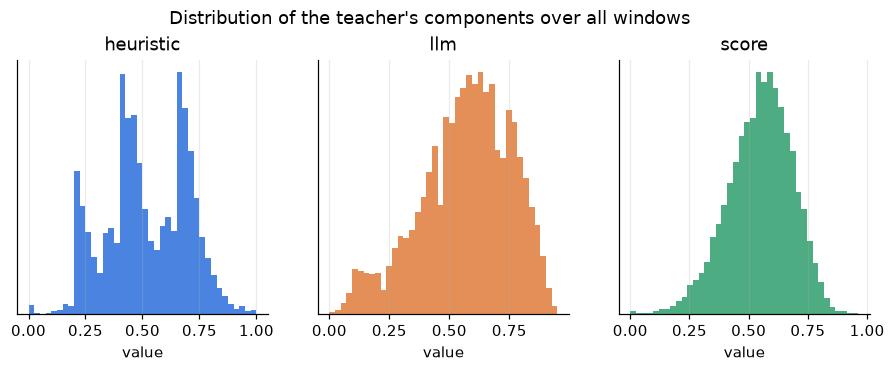

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(10, 3))
for ax, col, c in zip(axes, ["heuristic", "llm", "score"], COLORS):
    ax.hist(w[col], bins=40, color=c, alpha=0.85)
    ax.set(title=col, xlabel="value", yticks=[])
plt.suptitle("Distribution of the teacher's components over all windows", y=1.03)
plt.show()

The LLM component comes from integer judgements: the model rates 15-second blocks from 0 to 100,
and the result is rescaled to 0–1. Two passes, shifted by one block, are combined into one score
per window (`llm_scoring.mean_of_passes`). The LLM values cluster on round numbers, while the
heuristic is continuous.

## 2. The two signals measure different things

If the heuristic and the LLM agreed, one of them would be redundant. The report states that they
are uncorrelated over all windows (Pearson −0.009) and that per episode the correlation ranges
from −0.24 to 0.27.

In [5]:
r_all = stats.pearsonr(w.heuristic, w.llm).statistic
per_r = w.groupby("upload_id").apply(lambda g: stats.pearsonr(g.heuristic, g.llm).statistic, include_groups=False)
print(compare("Pearson(heuristic, LLM), all windows", r_all, -0.009, tol=0.0005))
print(compare("per-episode Pearson, minimum", per_r.min(), -0.24, tol=0.005))
print(compare("per-episode Pearson, maximum", per_r.max(), 0.27, tol=0.005))
print(f"Spearman, all windows: {stats.spearmanr(w.heuristic, w.llm).statistic:.3f}")

Pearson(heuristic, LLM), all windows: recomputed -0.0094 matches the report (-0.0090)
per-episode Pearson, minimum: recomputed -0.2368 matches the report (-0.2400)
per-episode Pearson, maximum: recomputed 0.2719 matches the report (0.2700)
Spearman, all windows: -0.016


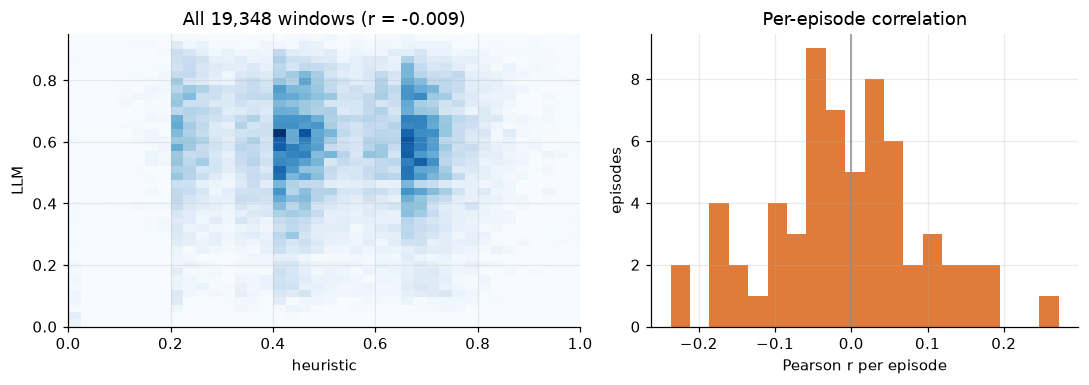

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), gridspec_kw={"width_ratios": [1.2, 1]})
axes[0].hist2d(w.heuristic, w.llm, bins=[40, 40], cmap="Blues")
axes[0].set(xlabel="heuristic", ylabel="LLM", title=f"All {len(w):,} windows (r = {r_all:.3f})")
axes[1].hist(per_r, bins=20, color=COLORS[1])
axes[1].axvline(0, color=GREY, lw=1)
axes[1].set(xlabel="Pearson r per episode", ylabel="episodes", title="Per-episode correlation")
plt.tight_layout()
plt.show()

## 3. One episode's curves

The curves of a test episode (upload 5, one of the three whose rendered clips the owner approved
in M15). The heuristic peaks at structural events, while the LLM rewards stretches of content.
Their weighted sum is the curve that the Shorts generator smooths and searches for peaks.

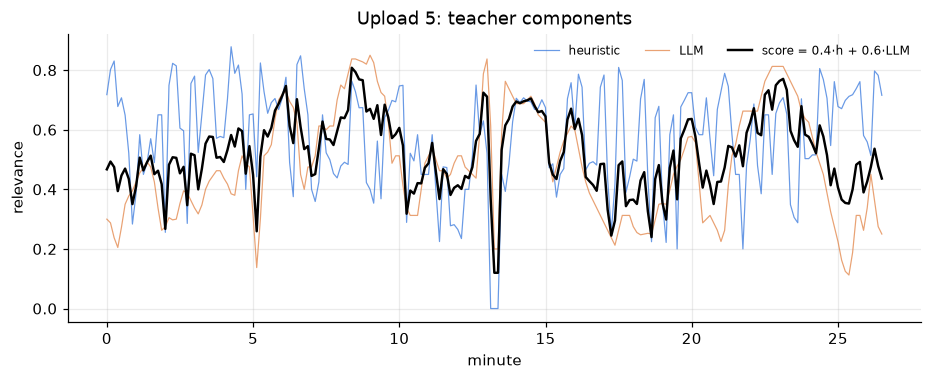

In [7]:
ep = w[w.upload_id == 5]
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.plot(ep.start / 60, ep.heuristic, lw=0.8, alpha=0.7, label="heuristic")
ax.plot(ep.start / 60, ep.llm, lw=0.8, alpha=0.7, label="LLM")
ax.plot(ep.start / 60, ep.score, lw=1.6, color="black", label="score = 0.4·h + 0.6·LLM")
ax.set(xlabel="minute", ylabel="relevance", title="Upload 5: teacher components")
ax.legend(ncol=3, frameon=False, fontsize=8, loc="upper right")
plt.show()

## 4. How stable is the LLM judgement?

The second finding of the report is that window-level relevance is a noisy judgement, even for the
teacher. The measurements of Table "Stability of the LLM relevance scores" come from three places:

| Comparison | Spearman | Where it was measured |
|---|---|---|
| Qwen3.5-4B, CPU vs. GPU prompt processing (whole episode / identical batches) | 0.53 / 0.74 | M9 runs, decision 0014 §3 |
| Qwen3.5-4B, agreement with the original CPU scores, one pass / two shifted passes | 0.66 / 0.72 | M9 runs, decision 0014 §3 |
| Qwen3.5-9B, aligned pass vs. shifted pass, 49 episodes | 0.49 | `experiments/m16-own-llm/07_evaluation.ipynb` (`qwen_pass_to_pass` = 0.4903) |

The 4B runs were one-off diagnostics on the old machine; their intermediate scores were not kept,
so this notebook cites them rather than recomputing them. The 9B value is recomputed in M16's
notebook 07 from both stored passes.

**Why it matters.** A trained student cannot be expected to match the teacher more closely than the
teacher matches itself. This sets the scale for the LLM-head result of notebook 03 (0.41).

## Summary

- 63 episodes, 19,348 windows of 15 s, all with both components.
- The heuristic and the LLM are uncorrelated over all windows and only weakly correlated within
  episodes, so the two signals carry different information. This shaped the trained model: it has
  one head per component.
- The LLM's own pass-to-pass agreement (Spearman 0.49 for the 9B) bounds what a student can learn
  from it.